# 01 — Analyse descriptive de la base welddb

**Objectif :** bien connaître la base avant de modéliser, et en déduire la liste des
traitements à faire (pré-processing) et le choix des variables cibles.

Plan :
1. Chargement et nettoyage du format
2. Structure de la base (lignes, soudures, publications)
3. Valeurs manquantes
4. Variables cibles (propriétés mécaniques)
5. Variables d'entrée (composition, procédé)
6. Corrélations
7. ACP
8. Bilan : traitements à faire et questions ouvertes

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
import welddb

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

## 1. Chargement et nettoyage du format

Le fichier brut contient 44 colonnes séparées par des espaces. `N` signifie **valeur non
publiée** (ce n'est pas zéro). Plusieurs colonnes numériques contiennent aussi du texte :

In [2]:
raw = welddb.load_raw()
print(raw.shape)

non_numeric = {}
for col in welddb.COLUMNS:
    if col in welddb.CATEGORICAL:
        continue
    s = raw[col].dropna()
    bad = s[pd.to_numeric(s, errors="coerce").isna()]
    if len(bad):
        non_numeric[col] = bad.value_counts().head(4).to_dict()
pd.Series(non_numeric, name="exemples de valeurs non numériques").to_frame()

(1652, 44)


,exemples de valeurs non numériques
S,{'<0.002': 7}
Mo,{'<0.01': 2}
V,"{'<0.0005': 266, '<0.01': 31, '<5': 9, '<0.005..."
Cu,{'<0.01': 14}
Co,{'<0.01': 21}
W,{'<0.1': 12}
Ti_ppm,"{'<100': 50, '<0.01': 16, '<5': 2, '<10': 2}"
N_ppm,"{'66totndres': 11, '67tot33res': 7, '61tot34re..."
Al_ppm,"{'<5': 343, '<100': 38, '<0.01': 16, '<50': 6}"
B_ppm,"{'<5': 395, '<10': 24}"


Choix faits dans `src/welddb.py` (à rappeler dans le rapport) :

| Cas | Exemple | Traitement |
|---|---|---|
| Sous la limite de détection | `<0.01`, `<5` | on garde la limite, et une colonne `<col>_below_dl` garde l'information |
| Plage | `150-200` (température entre passes) | milieu de la plage |
| Dureté annotée | `203(Hv30)`, `224Hv10` | valeur numérique (toutes en Vickers) |
| Azote total / résiduel | `66tot33res` | azote total |
| Polarité `0` | uniquement en courant AC | remplacée par `AC` |
| Types de soudure synonymes | `ShMA`, `SAA` | regroupés en `MMA`, `SA` |

On ajoute aussi une colonne `publication` (source bibliographique) déduite de l'identifiant.

In [3]:
df = welddb.load()
df.head()

,C,Si,Mn,S,S_below_dl,P,Ni,Cr,Mo,Mo_below_dl,V,V_below_dl,Cu,Cu_below_dl,Co,Co_below_dl,W,W_below_dl,O_ppm,Ti_ppm,Ti_ppm_below_dl,N_ppm,Al_ppm,Al_ppm_below_dl,B_ppm,B_ppm_below_dl,Nb_ppm,Nb_ppm_below_dl,Sn_ppm,Sn_ppm_below_dl,As_ppm,As_ppm_below_dl,Sb_ppm,Sb_ppm_below_dl,current_A,voltage_V,heat_input_kJmm,interpass_temp_C,pwht_temp_C,pwht_time_h,yield_strength_MPa,uts_MPa,elongation_pct,reduction_area_pct,charpy_temp_C,charpy_toughness_J,hardness,fatt50_C,primary_ferrite_pct,primary_ferrite_pct_below_dl,ferrite_second_phase_pct,acicular_ferrite_pct,martensite_pct,ferrite_carbide_pct,ac_dc,polarity,weld_type,weld_id,publication
0,0.037,0.30,0.65,0.008,False,0.012,0.0,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,False,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,170.0,21.0,1.0,200.0,250.0,14.0,392.0,466.0,31.9,80.6,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aaw,Evans-Ni/CMn-1990
1,0.037,0.30,0.65,0.008,False,0.012,0.0,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,False,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,170.0,21.0,1.0,200.0,0.0,0.0,NaN,NaN,NaN,NaN,-28.0,100.0,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aawch,Evans-Ni/CMn-1990
2,0.037,0.30,0.65,0.008,False,0.012,0.0,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,False,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,170.0,21.0,1.0,200.0,580.0,2.0,370.0,456.0,35.2,80.6,-38.0,100.0,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aht,Evans-Ni/CMn-1990
3,0.037,0.31,1.03,0.007,False,0.014,0.0,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,False,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,170.0,21.0,1.0,200.0,250.0,14.0,413.0,498.0,31.2,80.6,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Baw,Evans-Ni/CMn-1990
4,0.037,0.31,1.03,0.007,False,0.014,0.0,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,False,NaN,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,False,170.0,21.0,1.0,200.0,0.0,0.0,NaN,NaN,NaN,NaN,-48.0,100.0,NaN,NaN,32.0,False,28.0,40.0,0.0,0.0,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Bawch,Evans-Ni/CMn-1990


## 2. Structure de la base

1652 lignes, 1490 identifiants uniques, 148 publications


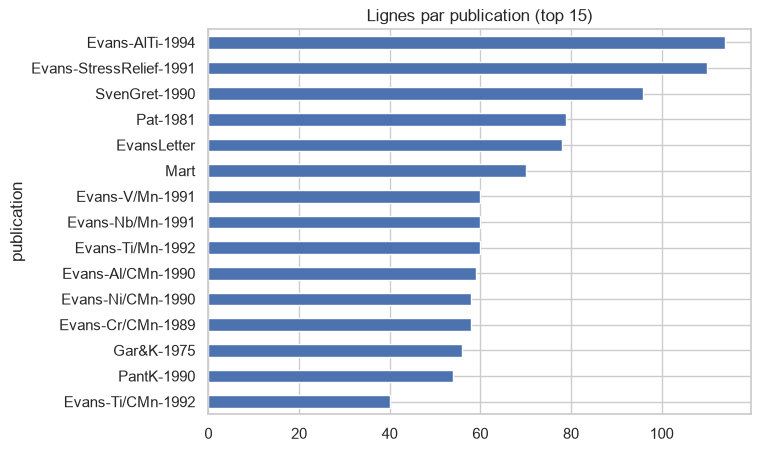

In [4]:
print(f"{len(df)} lignes, {df['weld_id'].nunique()} identifiants uniques, "
      f"{df['publication'].nunique()} publications")
df["publication"].value_counts().head(15).plot.barh(figsize=(7, 5), title="Lignes par publication (top 15)")
plt.gca().invert_yaxis();

**Point important :** une même soudure apparaît souvent sur plusieurs lignes. Dans les
données d'Evans par exemple, le suffixe de l'identifiant indique la mesure :
`aw` (brut de soudage, essai de traction), `awch` (brut de soudage, essai Charpy),
`ht` (après traitement thermique). Les compositions sont alors identiques :

In [5]:
df[df["weld_id"].str.startswith("Evans-Ni/CMn-1990/1991-0A")][
    ["weld_id", "C", "Mn", "pwht_temp_C", "yield_strength_MPa", "uts_MPa",
     "charpy_temp_C", "charpy_toughness_J"]]

,weld_id,C,Mn,pwht_temp_C,yield_strength_MPa,uts_MPa,charpy_temp_C,charpy_toughness_J
0,Evans-Ni/CMn-1990/1991-0Aaw,0.037,0.65,250.0,392.0,466.0,NaN,NaN
1,Evans-Ni/CMn-1990/1991-0Aawch,0.037,0.65,0.0,NaN,NaN,-28.0,100.0
2,Evans-Ni/CMn-1990/1991-0Aht,0.037,0.65,580.0,370.0,456.0,-38.0,100.0


In [6]:
inputs = welddb.COMPOSITION + welddb.PROCESS_NUM + welddb.PROCESS_CAT
n_dup = df.duplicated(subset=inputs, keep=False).sum()
print(f"{n_dup} lignes ont exactement les mêmes entrées qu'au moins une autre ligne")

887 lignes ont exactement les mêmes entrées qu'au moins une autre ligne


Conséquence pour la suite : un découpage aléatoire en train/test mettrait la même soudure
(ou des soudures quasi identiques d'une même étude) des deux côtés et donnerait des scores
trop optimistes. Il faudra une **validation croisée groupée** (`GroupKFold` par
publication, ou au minimum par soudure).

## 3. Valeurs manquantes

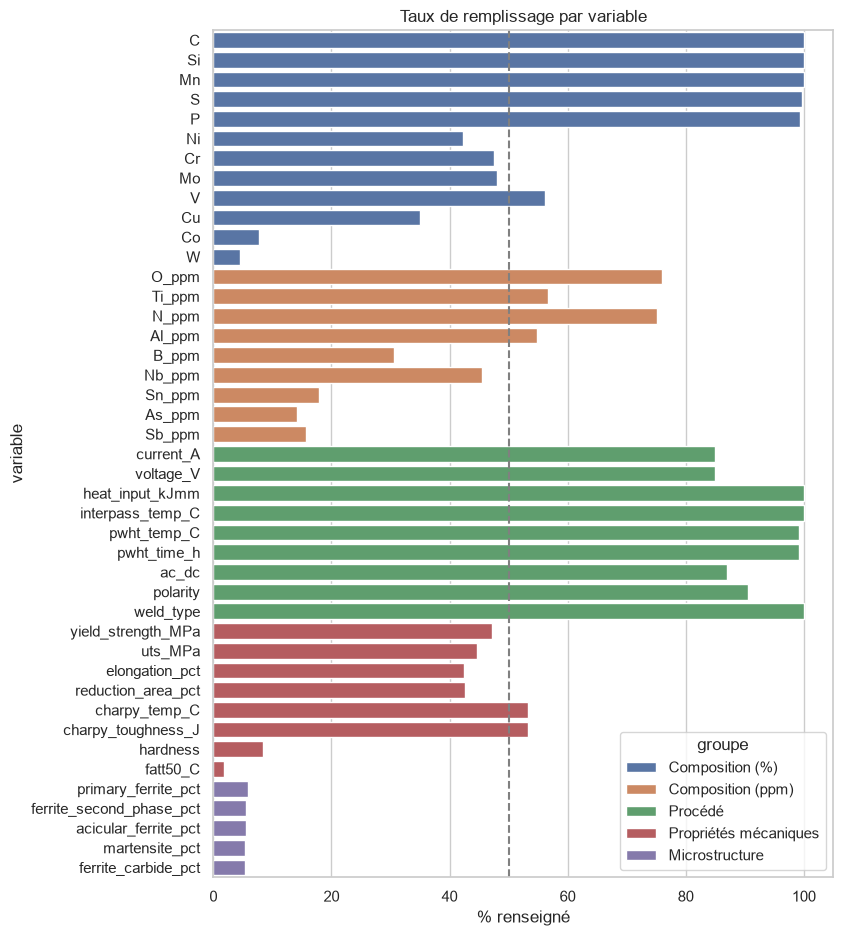

In [7]:
groups = {
    "Composition (%)": welddb.COMPOSITION_WT,
    "Composition (ppm)": welddb.COMPOSITION_PPM,
    "Procédé": welddb.PROCESS_NUM + welddb.PROCESS_CAT,
    "Propriétés mécaniques": welddb.MECHANICAL,
    "Microstructure": welddb.MICROSTRUCTURE,
}
rows = []
for g, cols in groups.items():
    for c in cols:
        rows.append({"groupe": g, "variable": c, "% renseigné": 100 * df[c].notna().mean()})
fill = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 11))
sns.barplot(data=fill, y="variable", x="% renseigné", hue="groupe", dodge=False, ax=ax)
ax.axvline(50, color="grey", ls="--")
ax.set_title("Taux de remplissage par variable");

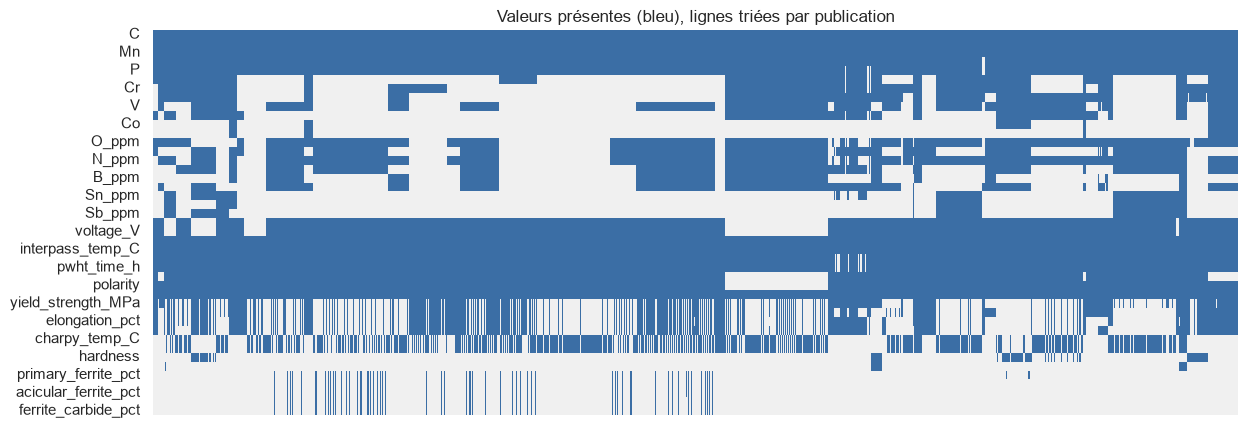

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
order = df.sort_values(["publication"]).index
sns.heatmap(df.loc[order, sum(groups.values(), [])].notna().T, cbar=False, ax=ax,
            cmap=["#f0f0f0", "#3b6ea5"], xticklabels=False)
ax.set_title("Valeurs présentes (bleu), lignes triées par publication");

Observations :
- C, Si, Mn, S, P, apport de chaleur, température entre passes et traitement thermique
  sont presque toujours renseignés.
- Les éléments d'alliage (Ni, Cr, Mo, V, Cu) et les éléments en ppm sont manquants par
  **blocs de publications** : un auteur ne mesure pas un élément, ou ne l'ajoute pas. Pour
  les éléments d'alliage, une valeur absente correspond très probablement à une teneur
  faible (élément non ajouté volontairement). L'imputation par 0 (ou une petite valeur
  résiduelle) est donc défendable pour eux, mais pas forcément pour O ou N, toujours présents
  dans une soudure.
- Co, W, la dureté, la FATT et la microstructure sont trop peu renseignés pour servir
  d'entrées ou de cibles.

## 4. Variables cibles : propriétés mécaniques

In [9]:
targets = ["yield_strength_MPa", "uts_MPa", "elongation_pct", "reduction_area_pct",
           "charpy_toughness_J"]
counts = df[targets + ["hardness", "fatt50_C"]].notna().sum()
print(counts.to_string())
has_any = df[targets].notna().any(axis=1)
print(f"\nLignes sans aucune cible : {(~has_any).sum()}")
print(f"Lignes avec limite élastique ET résilience Charpy : "
      f"{(df['yield_strength_MPa'].notna() & df['charpy_toughness_J'].notna()).sum()}")

yield_strength_MPa    780
uts_MPa               738
elongation_pct        700
reduction_area_pct    705
charpy_toughness_J    879
hardness              138
fatt50_C               31

Lignes sans aucune cible : 105
Lignes avec limite élastique ET résilience Charpy : 144


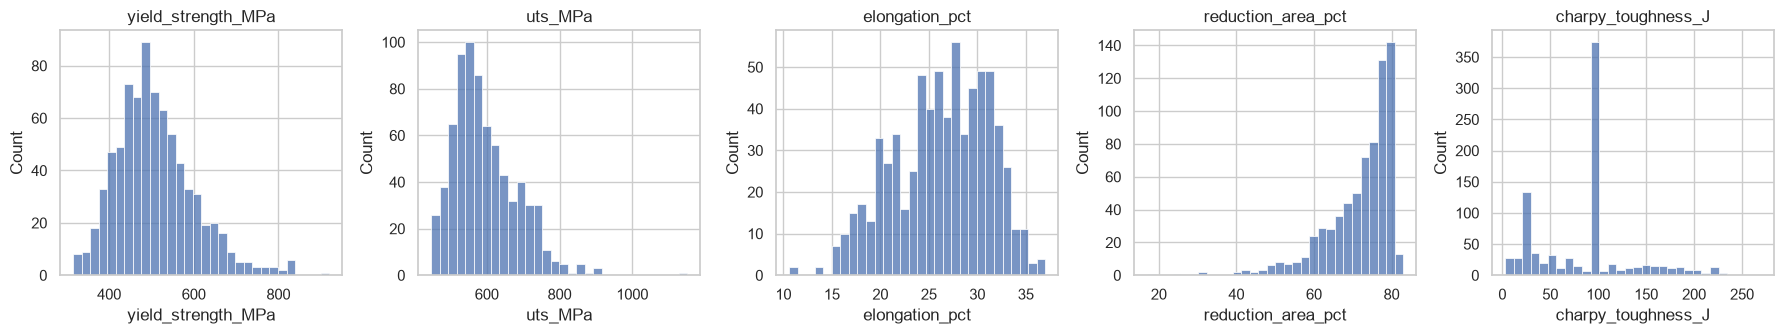

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, t in zip(axes, targets):
    sns.histplot(df[t].dropna(), ax=ax, bins=30)
    ax.set_title(t)
plt.tight_layout();

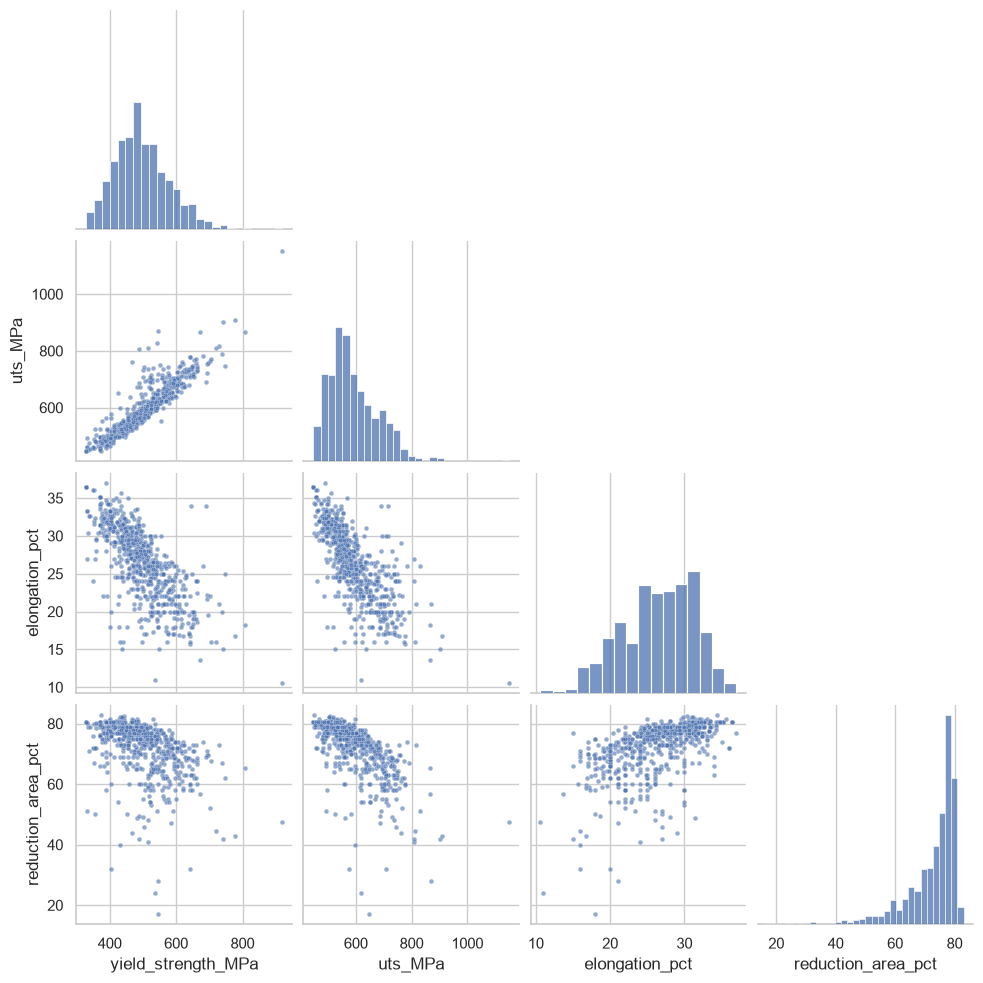

In [11]:
sns.pairplot(df[targets[:4]].dropna(), corner=True, plot_kws={"s": 12, "alpha": 0.6});

La limite d'élasticité et la résistance à la traction sont très corrélées : on peut les
prédire ensemble ou ne garder que l'une des deux. Allongement et striction mesurent la
ductilité et sont corrélés négativement à la résistance.

**Cas de la résilience Charpy :** l'énergie absorbée dépend fortement de la température
d'essai (transition ductile-fragile). Une valeur de Charpy n'a de sens qu'avec sa
température, qui devra être une entrée du modèle, ou bien il faudra ramener la cible à une
température de référence (ex. la température où l'énergie vaut 27 J ou 100 J, critère courant
dans les normes).

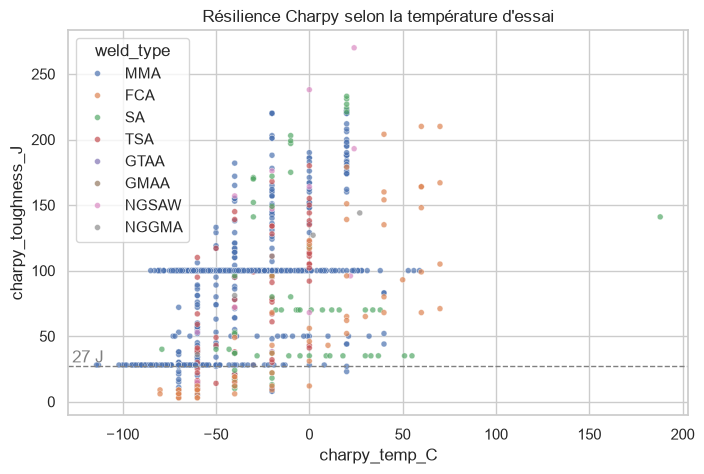

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="charpy_temp_C", y="charpy_toughness_J", hue="weld_type",
                s=18, alpha=0.7, ax=ax)
ax.axhline(27, color="grey", ls="--", lw=1)
ax.text(ax.get_xlim()[0] + 2, 30, "27 J", color="grey")
ax.set_title("Résilience Charpy selon la température d'essai");

In [13]:
print(df["charpy_temp_C"].value_counts().head(10).to_string())

charpy_temp_C
-20.0    76
-40.0    72
-60.0    69
 20.0    49
 0.0     47
-70.0    32
-50.0    29
-55.0    14
-30.0    13
-38.0    11


## 5. Variables d'entrée

In [14]:
desc = df[welddb.COMPOSITION + welddb.PROCESS_NUM].describe().T
desc["% renseigné"] = 100 * df[desc.index].notna().mean()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,% renseigné
C,1652.0,0.076,0.024,0.029,0.062,0.074,0.086,0.18,100.000
Si,1652.0,0.329,0.112,0.040,0.270,0.320,0.360,1.14,100.000
Mn,1652.0,1.203,0.382,0.270,0.940,1.270,1.440,2.25,100.000
S,1648.0,0.010,0.011,0.001,0.006,0.007,0.010,0.14,99.758
P,1642.0,0.013,0.020,0.002,0.007,0.010,0.014,0.25,99.395
Ni,697.0,0.415,0.787,0.000,0.000,0.067,0.260,3.50,42.191
Cr,784.0,2.101,3.027,0.000,0.000,0.530,2.300,10.20,47.458
Mo,793.0,0.479,0.477,0.000,0.000,0.340,1.010,1.50,48.002
V,928.0,0.097,0.493,0.000,0.000,0.010,0.044,5.00,56.174
Cu,578.0,0.172,0.323,0.000,0.000,0.030,0.180,1.63,34.988


**Unités.** Les colonnes sont dans des unités différentes : % massique pour les éléments
majeurs, ppm pour O, Ti, N, Al, B, Nb, Sn, As, Sb, et des unités physiques pour le procédé
(A, V, kJ/mm, °C, h). Les échelles vont de 10⁻³ à 10³ : **une standardisation est
nécessaire** pour l'ACP et pour les modèles sensibles à l'échelle (régression
régularisée, SVM, k-NN, réseaux de neurones), mais pas pour les arbres.

**Incohérences d'unités suspectes** : certaines valeurs des colonnes en ppm sont
inférieures à 1, ce qui ressemble à des valeurs saisies en % massique :

In [15]:
suspects = {c: (df[c].between(0, 1, inclusive="neither")).sum() for c in welddb.COMPOSITION_PPM}
pd.Series(suspects, name="nb valeurs dans ]0, 1[ ppm")

O_ppm      0
Ti_ppm    17
N_ppm      0
Al_ppm    26
B_ppm      0
Nb_ppm     0
Sn_ppm    90
As_ppm    90
Sb_ppm    90
Name: nb valeurs dans ]0, 1[ ppm, dtype: int64

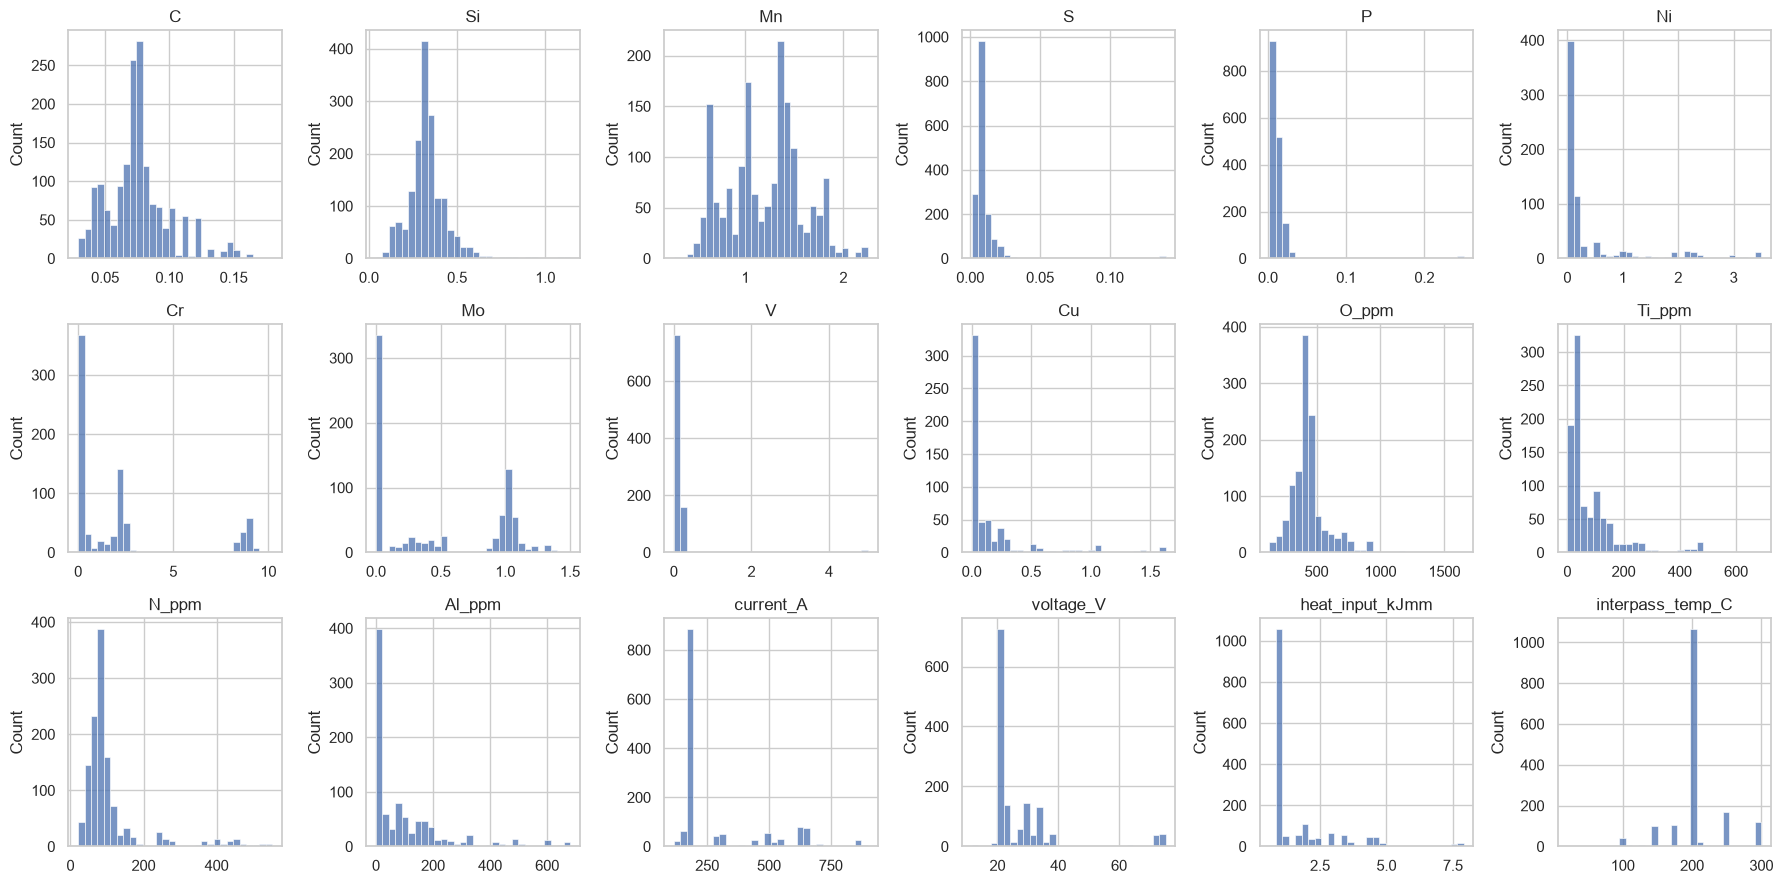

In [16]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
cols = ["C", "Si", "Mn", "S", "P", "Ni", "Cr", "Mo", "V", "Cu", "O_ppm", "Ti_ppm",
        "N_ppm", "Al_ppm", "current_A", "voltage_V", "heat_input_kJmm", "interpass_temp_C"]
for ax, c in zip(axes.flat, cols):
    sns.histplot(df[c].dropna(), ax=ax, bins=30)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout();

Plusieurs distributions sont très asymétriques (Ni, Cr, Mo, V, Cu, Ti, Al…) : la plupart
des soudures sont au carbone-manganèse, quelques-unes sont fortement alliées. Une
transformation (log ou `log1p`) pourra aider les modèles linéaires.

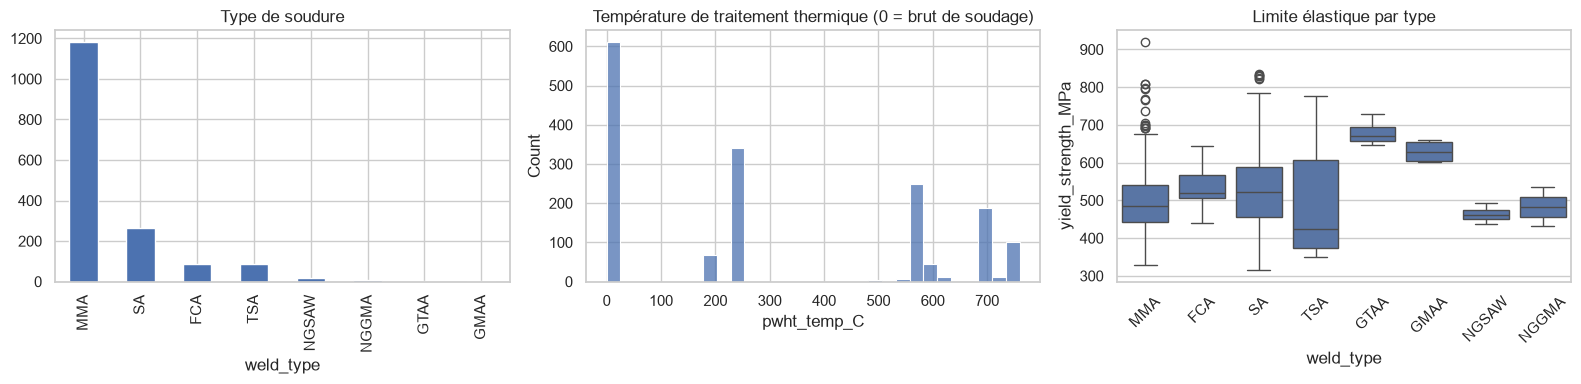

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["weld_type"].value_counts().plot.bar(ax=axes[0], title="Type de soudure")
sns.histplot(df["pwht_temp_C"], bins=30, ax=axes[1]).set_title("Température de traitement thermique (0 = brut de soudage)")
sns.boxplot(data=df, x="weld_type", y="yield_strength_MPa", ax=axes[2]).set_title("Limite élastique par type")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout();

## 6. Corrélations

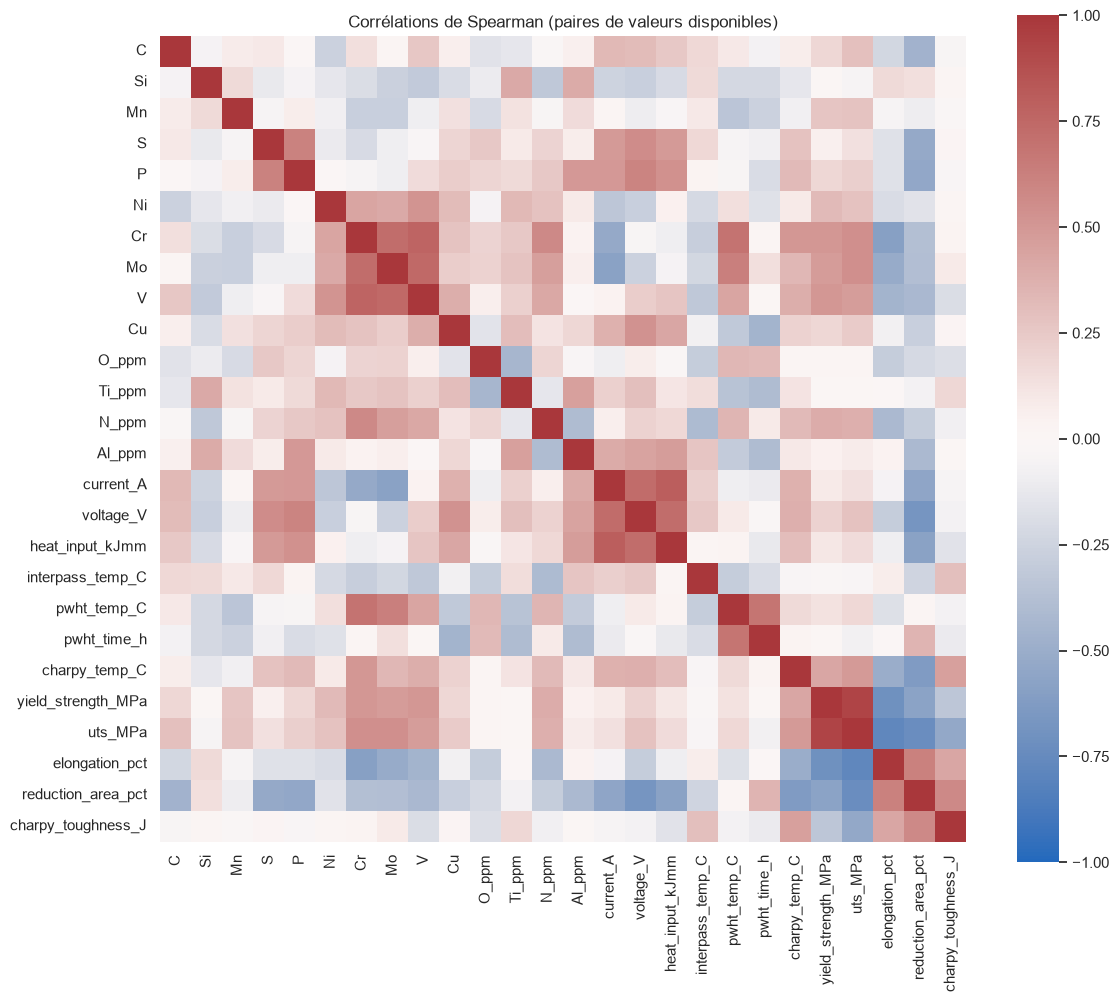

In [18]:
num_cols = (["C", "Si", "Mn", "S", "P", "Ni", "Cr", "Mo", "V", "Cu", "O_ppm", "Ti_ppm",
             "N_ppm", "Al_ppm", "current_A", "voltage_V", "heat_input_kJmm",
             "interpass_temp_C", "pwht_temp_C", "pwht_time_h", "charpy_temp_C"] + targets)
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Corrélations de Spearman (paires de valeurs disponibles)");

In [19]:
corr.loc[num_cols[:-len(targets)], targets].round(2).style.background_gradient(cmap="vlag", vmin=-1, vmax=1)

,yield_strength_MPa,uts_MPa,elongation_pct,reduction_area_pct,charpy_toughness_J
C,0.180000,0.290000,-0.230000,-0.460000,-0.040000
Si,0.010000,-0.050000,0.170000,0.140000,0.020000
Mn,0.270000,0.270000,-0.050000,-0.090000,-0.020000
S,0.060000,0.130000,-0.170000,-0.530000,0.020000
P,0.190000,0.220000,-0.170000,-0.540000,-0.040000
Ni,0.320000,0.280000,-0.200000,-0.160000,0.020000
Cr,0.500000,0.550000,-0.600000,-0.380000,0.030000
Mo,0.480000,0.540000,-0.520000,-0.390000,0.090000
V,0.510000,0.470000,-0.460000,-0.430000,-0.190000
Cu,0.180000,0.230000,-0.070000,-0.280000,0.030000


Attention : chaque coefficient est calculé sur les lignes où **les deux** variables sont
renseignées, donc sur des sous-ensembles différents. Ces corrélations donnent des pistes
mais peuvent refléter des différences entre publications plutôt que des effets physiques.

## 7. ACP

On garde les variables d'entrée assez renseignées. Pour cette exploration, les éléments
d'alliage absents sont mis à 0 (non ajoutés) et les autres manques sont remplacés par la
médiane ; on standardise ensuite. Ces choix seront revus pour la modélisation.

Composantes pour 80 % de variance : 10


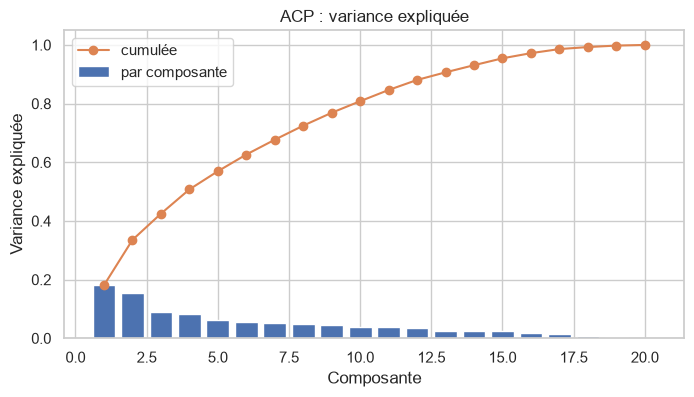

In [20]:
alloy = ["Ni", "Cr", "Mo", "V", "Cu"]
pca_cols = (["C", "Si", "Mn", "S", "P"] + alloy +
            ["O_ppm", "N_ppm", "Ti_ppm", "Al_ppm", "current_A", "voltage_V",
             "heat_input_kJmm", "interpass_temp_C", "pwht_temp_C", "pwht_time_h"])
X = df[pca_cols].copy()
X[alloy] = X[alloy].fillna(0)
X = X.fillna(X.median())
Xs = StandardScaler().fit_transform(X)

pca = PCA().fit(Xs)
Z = pca.transform(Xs)

fig, ax = plt.subplots(figsize=(8, 4))
ev = pca.explained_variance_ratio_
ax.bar(range(1, len(ev) + 1), ev, label="par composante")
ax.plot(range(1, len(ev) + 1), ev.cumsum(), "o-", color="C1", label="cumulée")
ax.set_xlabel("Composante"); ax.set_ylabel("Variance expliquée"); ax.legend()
ax.set_title("ACP : variance expliquée");
print("Composantes pour 80 % de variance :", np.argmax(ev.cumsum() >= 0.8) + 1)

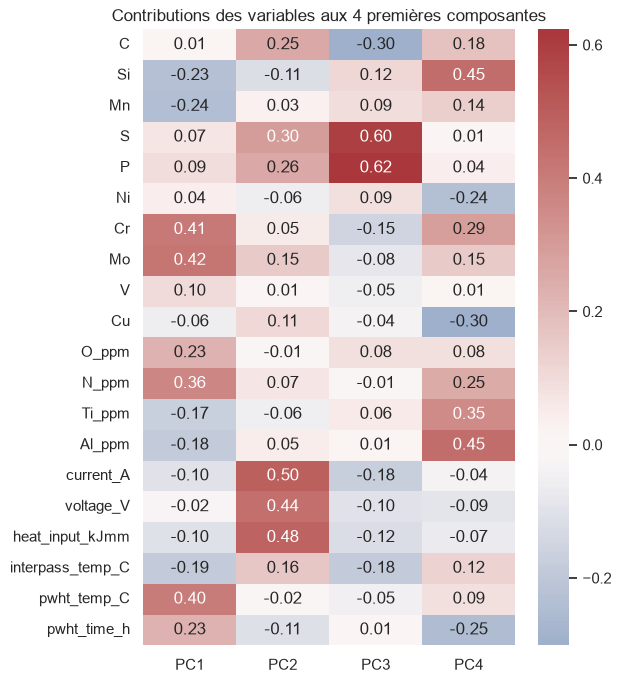

In [21]:
loadings = pd.DataFrame(pca.components_[:4].T, index=pca_cols,
                        columns=[f"PC{i}" for i in range(1, 5)])
fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(loadings, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Contributions des variables aux 4 premières composantes");

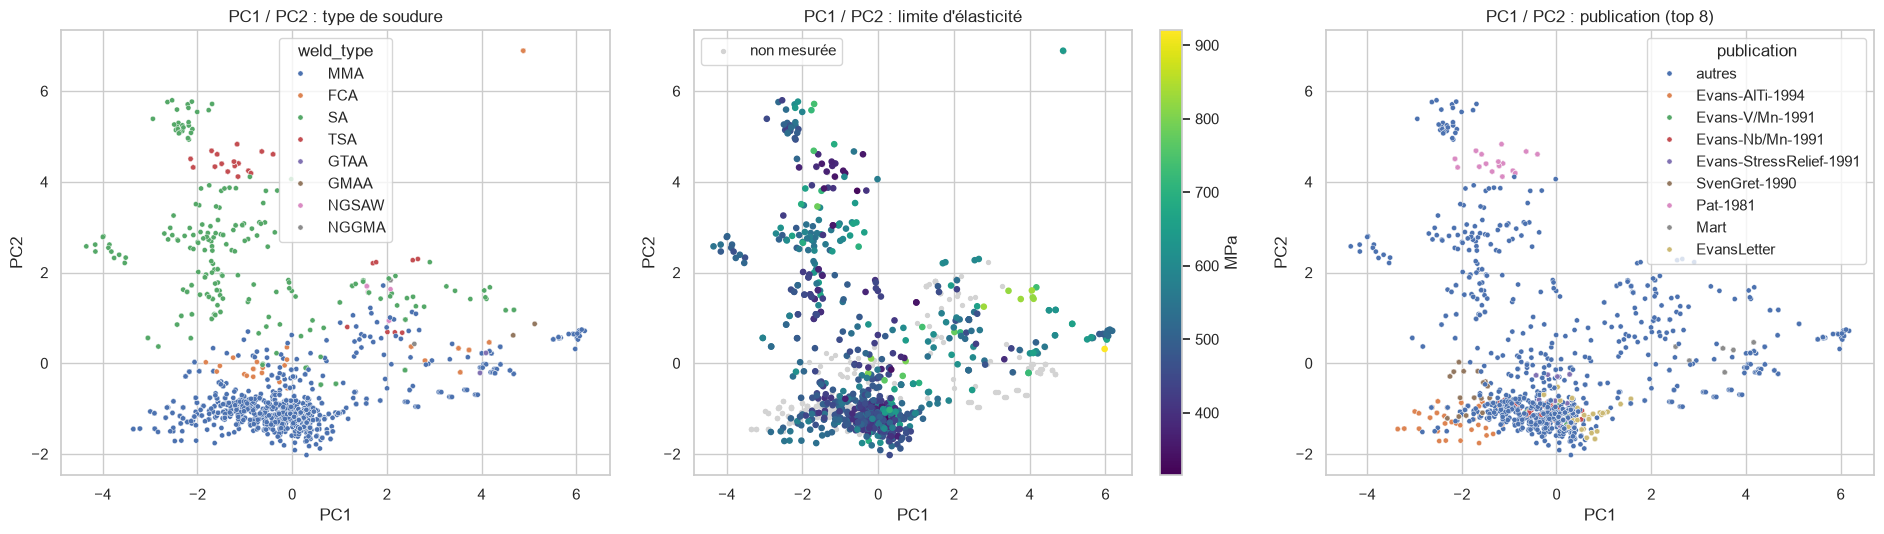

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["weld_type"], s=14, ax=axes[0])
axes[0].set_title("PC1 / PC2 : type de soudure")

has_ys = df["yield_strength_MPa"].notna()
axes[1].scatter(Z[~has_ys, 0], Z[~has_ys, 1], s=8, c="lightgrey", label="non mesurée")
sc = axes[1].scatter(Z[has_ys, 0], Z[has_ys, 1], s=14, c=df.loc[has_ys, "yield_strength_MPa"], cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="MPa"); axes[1].legend()
axes[1].set_title("PC1 / PC2 : limite d'élasticité")

top_pubs = df["publication"].value_counts().index[:8]
pub = df["publication"].where(df["publication"].isin(top_pubs), "autres")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=pub, s=14, ax=axes[2])
axes[2].set_title("PC1 / PC2 : publication (top 8)")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout();

Lecture de l'ACP :
- **PC1 = niveau d'alliage et traitement thermique** (Cr, Mo, N, température du traitement
  thermique) : à droite, les aciers alliés traités thermiquement, qui ont aussi les limites
  d'élasticité les plus élevées.
- **PC2 = énergie de soudage** (courant, tension, apport de chaleur) : elle sépare nettement
  l'arc submergé (SA, TSA, en haut) de l'arc manuel MMA (en bas).
- **PC3 = impuretés** (S, P).
- Il faut 10 composantes pour atteindre 80 % de variance : les entrées sont peu
  redondantes, et l'ACP ne réduira pas beaucoup la dimension.
- Les publications forment des groupes compacts (ex. Evans-AlTi-1994, Pat-1981) : cela
  confirme le besoin d'une validation croisée groupée.

## 8. Bilan

**Traitements à faire avant la modélisation**
1. Parsing du format (fait dans `src/welddb.py`) : `N` → manquant, `<x` → limite + drapeau,
   plages, annotations.
2. Corriger ou écarter les valeurs en ppm suspectes (< 1 ppm).
3. Imputation : 0 pour les éléments d'alliage non renseignés (à justifier), médiane ou
   imputation par modèle (KNN / itérative) pour O, N, courant, tension ; supprimer Co, W,
   la dureté, la FATT et la microstructure.
4. Encodage one-hot du type de soudure et de AC/DC (+ polarité).
5. Standardisation (et éventuellement `log1p` sur les variables asymétriques) pour les
   modèles non arborescents.
6. Validation croisée groupée par publication / soudure.

**Choix des cibles (à décider ensemble)**
- Résistance : limite d'élasticité (et/ou résistance à la traction).
- Ténacité : résilience Charpy, avec la température d'essai en entrée.
- Éventuellement ductilité (allongement).
- Ou une étiquette « bonne soudure » combinant résistance et ténacité (classification), au
  prix d'un seuil arbitraire et de très peu de lignes complètes.

**Semi-supervisé** : environ 50 % des lignes n'ont pas de limite d'élasticité, mais elles
ont des entrées complètes ; ce sont les données non étiquetées à exploiter.